# Recomendador de perfumes con notas y género

Este notebook analiza `data/fragrances_clean.csv` y recomienda perfumes por **notas aromáticas similares**. Usa directamente la columna `Gender` para filtrar candidatos masculinos, femeninos o unisex. Los acordes principales y los perfumistas identificados aportan señales secundarias. Cada resultado muestra las coincidencias que explican su puntuación.

In [8]:
from pathlib import Path
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfTransformer

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

## 1. Carga y calidad de los datos

El CSV usa punto y coma como separador y contiene caracteres Latin-1. Las URL identifican fichas; si alguna se repite, se conserva la fila con más información aromática. Las categorías de género se toman del propio archivo.

In [9]:
rutas = [Path("data/fragrances_clean.csv"), Path("../data/fragrances_clean.csv")]
ruta = next((p for p in rutas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError("No se encontró data/fragrances_clean.csv")
df = pd.read_csv(ruta, sep=";", encoding="latin-1", dtype=str, keep_default_na=False, low_memory=False)
columnas = ["Perfume", "Brand", "url", "Gender", "Top", "Middle", "Base",
            "mainaccord1", "mainaccord2", "mainaccord3", "mainaccord4", "mainaccord5"]
faltan = sorted(set(columnas) - set(df.columns))
if faltan:
    raise ValueError(f"Faltan columnas necesarias: {faltan}")
print(f"Archivo: {ruta} · {len(df):,} filas × {len(df.columns)} columnas")
display(pd.DataFrame({"columna": df.columns,
                      "con valor": [df[c].astype(str).str.strip().ne("").sum() for c in df.columns]}))
print(f"Filas totalmente duplicadas: {df.duplicated().sum():,}")
print(f"URL repetidas: {df['url'].duplicated().sum():,}")
print("Valores originales de Gender:")
display(df["Gender"].value_counts().to_frame("perfumes"))
display(df[columnas].head())

Archivo: ../data/fragrances_clean.csv · 24,063 filas × 18 columnas


,columna,con valor
0,url,24063
1,Perfume,24063
2,Brand,24063
3,Country,24063
4,Gender,24063
5,Rating Value,24063
6,Rating Count,24063
7,Year,22026
8,Top,24063
9,Middle,24063


Filas totalmente duplicadas: 0
URL repetidas: 0
Valores originales de Gender:


,perfumes
Gender,
women,11376
unisex,7698
men,4989


,Perfume,Brand,url,Gender,Top,Middle,Base,mainaccord1,mainaccord2,mainaccord3,mainaccord4,mainaccord5
0,accento-overdose-pride-edition,xerjoff,https://www.fragrantica.com/perfume/xerjoff/accento-overdose-pride-edition-74630.html,unisex,"fruity notes, aldehydes, green notes","bulgarian rose, egyptian jasmine, lily-of-the-valley","eucalyptus, pine",rose,woody,fruity,aromatic,floral
1,classique-pride-2024,jean-paul-gaultier,https://www.fragrantica.com/perfume/jean-paul-gaultier/classique-pride-2024-90394.html,women,"yuzu, citruses","orange blossom, neroli","musk, blonde woods",citrus,white floral,sweet,fresh,musky
2,classique-pride-2023,jean-paul-gaultier,https://www.fragrantica.com/perfume/jean-paul-gaultier/classique-pride-2023-81775.html,unisex,"blood orange, yuzu","neroli, orange blossom","musk, white woods",citrus,white floral,sweet,fresh spicy,musky
3,pride-edition-man,bruno-banani,https://www.fragrantica.com/perfume/bruno-banani/pride-edition-man-55514.html,men,"guarana, grapefruit, red apple","walnut, lavender, guava","vetiver, benzoin, amber",fruity,nutty,woody,tropical,
4,le-male-pride-collector,jean-paul-gaultier,https://www.fragrantica.com/perfume/jean-paul-gaultier/le-male-pride-collector-60765.html,men,"mint, lavender, cardamom, artemisia, bergamot","caraway, cinnamon, orange blossom","vanilla, sandalwood, amber, cedar, tonka bean",aromatic,warm spicy,fresh spicy,cinnamon,vanilla


## 2. Preparación del catálogo

Las notas de salida, corazón y fondo se separan por comas sin romper nombres compuestos. Se normalizan acentos y mayúsculas. Si una nota aparece en varias etapas se conserva su mayor peso. Los cinco acordes principales se mantienen separados de las notas. `men`, `women` y `unisex` se traducen a las categorías del recomendador; cualquier otro valor queda como `desconocido`.

In [10]:
AUSENTES = {"", "na", "n a", "nan", "none", "null", "unknown", "not available"}
PESO_ETAPA = {"Top": 1.0, "Middle": 1.15, "Base": 1.3}
COLUMNAS_ACORDES = [f"mainaccord{i}" for i in range(1, 6)]
MAPA_GENERO = {"men": "hombre", "women": "mujer", "unisex": "unisex"}


def normalizar(valor):
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFKD", str(valor).strip())
    texto = "".join(c for c in texto if not unicodedata.combining(c)).casefold()
    texto = re.sub(r"[^a-z0-9]+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def separar(valor):
    if pd.isna(valor):
        return []
    return list(dict.fromkeys(
        nota for parte in re.split(r"[,;|\n]+", str(valor))
        if (nota := normalizar(parte)) and nota not in AUSENTES
    ))


def extraer_notas(fila):
    notas = {}
    for columna, peso in PESO_ETAPA.items():
        for nota in separar(fila[columna]):
            notas[nota] = max(notas.get(nota, 0), peso)
    return notas


def extraer_acordes(fila):
    # El primer acorde representa mejor el perfil principal de la ficha.
    acordes = {}
    for posicion, columna in enumerate(COLUMNAS_ACORDES):
        acorde = normalizar(fila[columna])
        if acorde and acorde not in AUSENTES:
            acordes[acorde] = max(acordes.get(acorde, 0), 1 - 0.1 * posicion)
    return acordes


def extraer_perfumistas(fila):
    nombres = set()
    for columna in ("Perfumer1", "Perfumer2"):
        if columna in fila:
            nombres.update(separar(fila[columna]))
    return nombres


catalogo = df.loc[df["url"].str.strip().ne("") & df["Perfume"].str.strip().ne("")].copy()
catalogo["__orden"] = np.arange(len(catalogo))
catalogo["notas"] = catalogo.apply(extraer_notas, axis=1)
catalogo["acordes"] = catalogo.apply(extraer_acordes, axis=1)
catalogo["perfumistas"] = catalogo.apply(extraer_perfumistas, axis=1)
catalogo["genero"] = catalogo["Gender"].str.strip().str.casefold().map(MAPA_GENERO).fillna("desconocido")
catalogo["nombre_mostrado"] = catalogo["Perfume"].str.replace("-", " ", regex=False).str.title()
catalogo["__completitud"] = catalogo["notas"].map(len) + catalogo["acordes"].map(len)
catalogo = (catalogo.sort_values(["__completitud", "__orden"], ascending=[False, True])
            .drop_duplicates(subset=["url"], keep="first")
            .sort_values("__orden").reset_index(drop=True))
catalogo["id_perfume"] = np.arange(len(catalogo), dtype=int)
catalogo["tiene_notas"] = catalogo["notas"].map(bool)
print(f"Catálogo: {len(catalogo):,} fichas; con notas: {catalogo['tiene_notas'].sum():,}; sin notas: {(~catalogo['tiene_notas']).sum():,}")
display(catalogo["genero"].value_counts().rename_axis("público objetivo").to_frame("perfumes"))
display(catalogo[["id_perfume", "Brand", "nombre_mostrado", "genero", "notas", "acordes"]].head(10))

Catálogo: 24,063 fichas; con notas: 24,063; sin notas: 0


,perfumes
público objetivo,
mujer,11376
unisex,7698
hombre,4989


,id_perfume,Brand,nombre_mostrado,genero,notas,acordes
0,0,xerjoff,Accento Overdose Pride Edition,unisex,"{'fruity notes': 1.0, 'aldehydes': 1.0, 'green notes': 1.0, 'bulgarian rose': 1.15, 'egyptian ja...","{'rose': 1.0, 'woody': 0.9, 'fruity': 0.8, 'aromatic': 0.7, 'floral': 0.6}"
1,1,jean-paul-gaultier,Classique Pride 2024,mujer,"{'yuzu': 1.0, 'citruses': 1.0, 'orange blossom': 1.15, 'neroli': 1.15, 'musk': 1.3, 'blonde wood...","{'citrus': 1.0, 'white floral': 0.9, 'sweet': 0.8, 'fresh': 0.7, 'musky': 0.6}"
2,2,jean-paul-gaultier,Classique Pride 2023,unisex,"{'blood orange': 1.0, 'yuzu': 1.0, 'neroli': 1.15, 'orange blossom': 1.15, 'musk': 1.3, 'white w...","{'citrus': 1.0, 'white floral': 0.9, 'sweet': 0.8, 'fresh spicy': 0.7, 'musky': 0.6}"
3,3,bruno-banani,Pride Edition Man,hombre,"{'guarana': 1.0, 'grapefruit': 1.0, 'red apple': 1.0, 'walnut': 1.15, 'lavender': 1.15, 'guava':...","{'fruity': 1.0, 'nutty': 0.9, 'woody': 0.8, 'tropical': 0.7}"
4,4,jean-paul-gaultier,Le Male Pride Collector,hombre,"{'mint': 1.0, 'lavender': 1.0, 'cardamom': 1.0, 'artemisia': 1.0, 'bergamot': 1.0, 'caraway': 1....","{'aromatic': 1.0, 'warm spicy': 0.9, 'fresh spicy': 0.8, 'cinnamon': 0.7, 'vanilla': 0.6}"
5,5,jean-paul-gaultier,Le Male Pride 2023,hombre,"{'yuzu': 1.0, 'blood orange': 1.0, 'neroli': 1.15, 'orange blossom': 1.15, 'musk': 1.3, 'white w...","{'citrus': 1.0, 'white floral': 0.9, 'sweet': 0.8, 'fresh spicy': 0.7, 'green': 0.6}"
6,6,jean-paul-gaultier,Le Male Pride 2024,hombre,"{'citruses': 1.0, 'yuzu': 1.0, 'neroli': 1.15, 'orange blossom': 1.15, 'woodsy notes': 1.3, 'mus...","{'white floral': 1.0, 'citrus': 0.9, 'fresh': 0.8, 'soapy': 0.7}"
7,7,ralph-lauren,Polo Red Pride Edition,hombre,"{'cranberry': 1.0, 'pink grapefruit': 1.0, 'citron': 1.0, 'clary sage': 1.15, 'lavender': 1.15, ...","{'woody': 1.0, 'amber': 0.9, 'citrus': 0.8, 'warm spicy': 0.7, 'aromatic': 0.6}"
8,8,ralph-lauren,Ralph Pride Edition,mujer,"{'tangerine': 1.0, 'green apple': 1.0, 'freesia': 1.0, 'magnolia': 1.15, 'lime linden blossom': ...","{'citrus': 1.0, 'fruity': 0.9, 'floral': 0.8, 'sweet': 0.7, 'green': 0.6}"
9,9,we-pink,Waffle,mujer,"{'strawberry': 1.0, 'almond': 1.0, 'raspberry': 1.0, 'butter': 1.15, 'peach blossom': 1.15, 'vio...","{'powdery': 1.0, 'musky': 0.9, 'violet': 0.8, 'fruity': 0.7, 'fresh': 0.6}"


## 3. Cobertura y notas frecuentes

La frecuencia de notas cuenta perfumes, no menciones repetidas dentro de una misma ficha. Las filas sin notas se muestran en la cobertura del catálogo pero no pueden ser origen ni candidato de una recomendación aromática.

Notas únicas: 1,668


,Perfumes
musk,10951
bergamot,8612
sandalwood,8009
amber,7686
jasmine,7673
patchouli,7208
vanilla,6666
rose,6134
cedar,5582
mandarin orange,4006


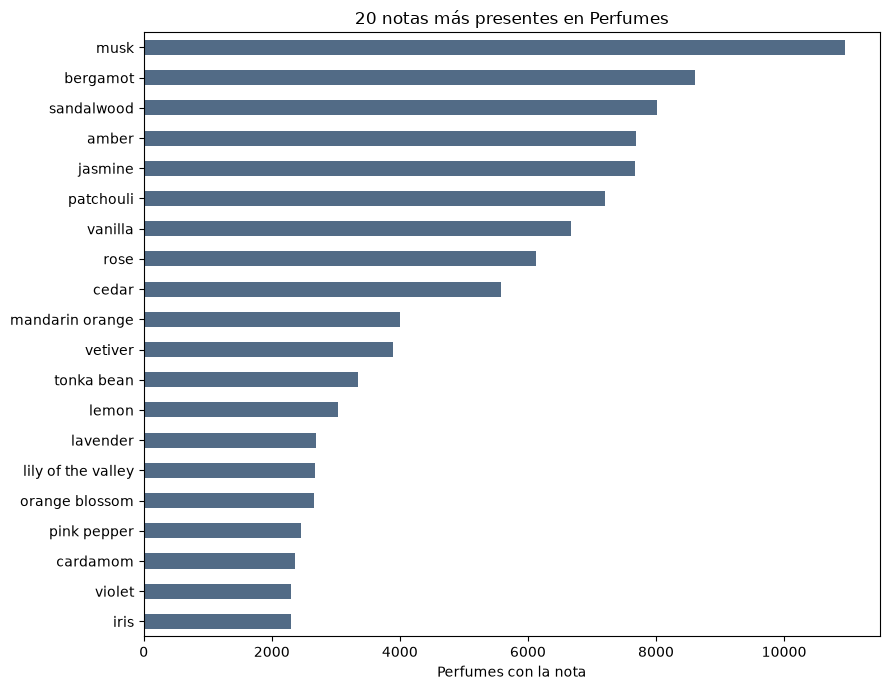

In [11]:
frecuencias = Counter(nota for notas in catalogo["notas"] for nota in notas)
print(f"Notas únicas: {len(frecuencias):,}")
top = pd.Series(dict(frecuencias.most_common(20)), name="Perfumes").sort_values()
display(top.sort_values(ascending=False).to_frame())
ax = top.plot.barh(figsize=(9, 7), color="#526b86", title="20 notas más presentes en Perfumes")
ax.set_xlabel("Perfumes con la nota")
plt.tight_layout()
plt.show()

## 4. Modelo de similitud

TF-IDF reduce el peso de notas muy frecuentes y el coseno compara los perfiles. La puntuación combina **75 % notas**, **20 % acordes** y **5 % perfumistas compartidos** cuando estén identificados. Se exige al menos una nota compartida: los metadatos solos no bastan para recomendar. La calificación de usuarios se deja fuera porque mide valoración y no parecido aromático.

In [12]:
vectorizador_notas = DictVectorizer(sparse=True)
matriz_notas = vectorizador_notas.fit_transform(catalogo["notas"])
matriz_notas = TfidfTransformer(norm="l2").fit_transform(matriz_notas).tocsr()
vectorizador_acordes = DictVectorizer(sparse=True)
matriz_acordes = vectorizador_acordes.fit_transform(catalogo["acordes"])
matriz_acordes = TfidfTransformer(norm="l2").fit_transform(matriz_acordes).tocsr()
print(f"Matriz de notas: {matriz_notas.shape[0]:,} × {matriz_notas.shape[1]:,}")
print(f"Matriz de acordes: {matriz_acordes.shape[0]:,} × {matriz_acordes.shape[1]:,}")

Matriz de notas: 24,063 × 1,668
Matriz de acordes: 24,063 × 84


## 5. Recomendar

`genero="hombre"` incluye perfumes `men` y `unisex`; `genero="mujer"` incluye `women` y `unisex`. `genero="unisex"` solo incluye unisex y `genero="todos"` permite las tres categorías. El filtro se aplica a los candidatos y usa la columna `Gender` del CSV.

In [13]:
CATEGORIAS = {
    "todos": {"hombre", "mujer", "unisex"},
    "hombre": {"hombre", "unisex"},
    "mujer": {"mujer", "unisex"},
    "unisex": {"unisex"},
}


def resolver_perfume(perfume):
    if isinstance(perfume, (int, np.integer)) or str(perfume).isdigit():
        indice = int(perfume)
        if 0 <= indice < len(catalogo):
            return indice
        raise ValueError("ID fuera del catálogo")
    coincidencias = catalogo[catalogo["nombre_mostrado"].str.casefold() == str(perfume).strip().casefold()]
    if len(coincidencias) != 1:
        raise ValueError("Nombre ausente o ambiguo; usa el ID mostrado en el catálogo.")
    return int(coincidencias.iloc[0]["id_perfume"])


def recomendar_perfumes(perfume, genero="todos", limite=5):
    """Ordena perfumes distintos por similitud aromática y filtra el Gender del CSV."""
    preferencia = str(genero).strip().casefold()
    if preferencia not in CATEGORIAS:
        raise ValueError("Usa genero='todos', 'hombre', 'mujer' o 'unisex'.")
    origen_id = resolver_perfume(perfume)
    origen = catalogo.iloc[origen_id]
    if not origen["tiene_notas"]:
        print("El perfume elegido no tiene notas utilizables.")
        return pd.DataFrame()
    semejanza_notas = (matriz_notas @ matriz_notas[origen_id].T).toarray().ravel()
    semejanza_acordes = (matriz_acordes @ matriz_acordes[origen_id].T).toarray().ravel()
    mascara = (semejanza_notas > 0) & catalogo["genero"].isin(CATEGORIAS[preferencia]).to_numpy()
    mascara[origen_id] = False
    indices = np.flatnonzero(mascara)
    if len(indices) == 0:
        print("No hay otro perfume con una nota compartida en el público seleccionado.")
        return pd.DataFrame()
    perfumistas_origen = origen["perfumistas"]
    mismo_perfumista = np.array([
        bool(perfumistas_origen & catalogo.iloc[int(indice)]["perfumistas"])
        for indice in indices
    ], dtype=float)
    puntajes = 100 * (0.75 * semejanza_notas[indices]
                     + 0.20 * semejanza_acordes[indices]
                     + 0.05 * mismo_perfumista)
    orden = np.lexsort((indices, -semejanza_notas[indices], -puntajes))[:max(int(limite), 0)]
    filas = []
    for posicion in orden:
        indice = int(indices[posicion])
        candidato = catalogo.iloc[indice]
        compartidas = sorted(set(origen["notas"]) & set(candidato["notas"]))
        acuerdos = sorted(set(origen["acordes"]) & set(candidato["acordes"]))
        perfumistas = sorted(perfumistas_origen & candidato["perfumistas"])
        filas.append({
            "ID": indice, "Perfume": candidato["nombre_mostrado"], "Marca": candidato["Brand"],
            "Género": candidato["genero"], "Puntuación / 100": round(float(puntajes[posicion]), 2),
            "Notas compartidas": ", ".join(compartidas),
            "Acordes compartidos": ", ".join(acuerdos) or "ninguno",
            "Perfumista compartido": ", ".join(perfumistas) or "ninguno",
            "Similitud notas (%)": round(100 * float(semejanza_notas[indice]), 1),
            "Similitud acordes (%)": round(100 * float(semejanza_acordes[indice]), 1),
            "URL": candidato["url"],
        })
    print(f"Origen: {origen['Brand']} — {origen['nombre_mostrado']} (ID {origen_id}); filtro: {preferencia}")
    return pd.DataFrame(filas)


display(catalogo.loc[catalogo["tiene_notas"], ["id_perfume", "Brand", "nombre_mostrado", "genero"]].head(15))

,id_perfume,Brand,nombre_mostrado,genero
0,0,xerjoff,Accento Overdose Pride Edition,unisex
1,1,jean-paul-gaultier,Classique Pride 2024,mujer
2,2,jean-paul-gaultier,Classique Pride 2023,unisex
3,3,bruno-banani,Pride Edition Man,hombre
4,4,jean-paul-gaultier,Le Male Pride Collector,hombre
5,5,jean-paul-gaultier,Le Male Pride 2023,hombre
6,6,jean-paul-gaultier,Le Male Pride 2024,hombre
7,7,ralph-lauren,Polo Red Pride Edition,hombre
8,8,ralph-lauren,Ralph Pride Edition,mujer
9,9,we-pink,Waffle,mujer


## 6. Ejemplos y alcance

Los ejemplos seleccionan perfumes reales con candidatos de notas compartidas para cada público. Las puntuaciones miden parecido dentro de este catálogo; no están calibradas con preferencias personales.

In [14]:
for preferencia in ("hombre", "mujer", "unisex"):
    fuentes = catalogo[catalogo["tiene_notas"] & (catalogo["genero"] == preferencia)]
    if fuentes.empty:
        print(f"Sin fuentes para {preferencia}")
        continue
    ejemplo = None
    candidatos_validos = catalogo["genero"].isin(CATEGORIAS[preferencia]).to_numpy()
    for indice in fuentes["id_perfume"].astype(int):
        coincidencias = (matriz_notas @ matriz_notas[indice].T).toarray().ravel() > 0
        coincidencias[indice] = False
        if np.any(coincidencias & candidatos_validos):
            ejemplo = indice
            break
    if ejemplo is None:
        print(f"Sin pares con notas compartidas para {preferencia}")
        continue
    display(recomendar_perfumes(ejemplo, genero=preferencia, limite=5))

Origen: bruno-banani — Pride Edition Man (ID 3); filtro: hombre


,ID,Perfume,Marca,Género,Puntuación / 100,Notas compartidas,Acordes compartidos,Perfumista compartido,Similitud notas (%),Similitud acordes (%),URL
0,5383,Bruno Banani No Limits Man,bruno-banani,hombre,73.84,"amber, grapefruit, guarana, red apple, vetiver, walnut","fruity, nutty, woody",ninguno,78.8,73.8,https://www.fragrantica.com/perfume/bruno-banani/bruno-banani-no-limits-man-40779.html
1,14569,Secret Sucre,molinard,unisex,38.24,"amber, benzoin, walnut","nutty, woody",ninguno,36.5,54.5,https://www.fragrantica.com/perfume/molinard/secret-sucre-24882.html
2,3757,Attendre Esperer,frapin,unisex,32.81,walnut,"nutty, woody",ninguno,28.5,57.2,https://www.fragrantica.com/perfume/frapin/attendre-esperer-80473.html
3,22974,Sotoor Waaw,rasasi,unisex,28.68,"amber, lavender, vetiver, walnut",woody,ninguno,36.4,7.0,https://www.fragrantica.com/perfume/rasasi/sotoor-waaw-47930.html
4,11800,Hawaiian Ruby Guava,pacifica,unisex,28.65,guava,"fruity, tropical",ninguno,26.8,42.9,https://www.fragrantica.com/perfume/pacifica/hawaiian-ruby-guava-6784.html


Origen: jean-paul-gaultier — Classique Pride 2024 (ID 1); filtro: mujer


,ID,Perfume,Marca,Género,Puntuación / 100,Notas compartidas,Acordes compartidos,Perfumista compartido,Similitud notas (%),Similitud acordes (%),URL
0,18826,Chai Epice,le-monde-gourmand,mujer,58.44,"blonde woods, musk","musky, sweet",ninguno,67.1,40.4,https://www.fragrantica.com/perfume/le-monde-gourmand/chai-epice-72662.html
1,5091,Girl Of Now Rose Petal,elie-saab,mujer,46.81,blonde woods,musky,ninguno,57.5,18.2,https://www.fragrantica.com/perfume/elie-saab/girl-of-now-rose-petal-90951.html
2,21937,Noble Epine,l-occitane-en-provence,unisex,44.84,"blonde woods, musk","musky, sweet",ninguno,52.7,26.5,https://www.fragrantica.com/perfume/l-occitane-en-provence/noble-epine-87134.html
3,7800,Flora Gorgeous Magnolia,gucci,mujer,43.63,"blonde woods, musk","musky, sweet",ninguno,52.4,21.6,https://www.fragrantica.com/perfume/gucci/flora-gorgeous-magnolia-83621.html
4,2,Classique Pride 2023,jean-paul-gaultier,unisex,43.62,"musk, neroli, orange blossom, yuzu","citrus, musky, sweet, white floral",ninguno,36.9,79.6,https://www.fragrantica.com/perfume/jean-paul-gaultier/classique-pride-2023-81775.html


Origen: xerjoff — Accento Overdose Pride Edition (ID 0); filtro: unisex


,ID,Perfume,Marca,Género,Puntuación / 100,Notas compartidas,Acordes compartidos,Perfumista compartido,Similitud notas (%),Similitud acordes (%),URL
0,12651,Accento Overdose,xerjoff,unisex,71.16,"aldehydes, bulgarian rose, egyptian jasmine, eucalyptus, fruity notes, lily of the valley, pine","fruity, woody",ninguno,88.7,23.3,https://www.fragrantica.com/perfume/xerjoff/accento-overdose-56097.html
1,9144,Sports Car Club,penhaligon-s,unisex,41.48,"eucalyptus, pine","aromatic, woody",ninguno,47.9,27.6,https://www.fragrantica.com/perfume/penhaligon-s/sports-car-club-73924.html
2,14970,Isotta,v-canto,unisex,35.93,"bulgarian rose, eucalyptus","aromatic, rose, woody",ninguno,31.4,61.8,https://www.fragrantica.com/perfume/v-canto/isotta-61869.html
3,23052,Infini Rose,maison-alhambra,unisex,34.30,"bulgarian rose, egyptian jasmine","floral, rose",ninguno,29.8,59.8,https://www.fragrantica.com/perfume/maison-alhambra/infini-rose-83513.html
4,20846,Atomic Rose,initio-parfums-prives,unisex,34.05,"bulgarian rose, egyptian jasmine","floral, rose",ninguno,32.8,47.1,https://www.fragrantica.com/perfume/initio-parfums-prives/atomic-rose-57587.html
